In [2]:
from pathlib import Path
from typing import Optional

import bathyreq
import cmasher as cmr
import cmocean
import numpy as np
import matplotlib.colors as colors
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from mpl_toolkits.basemap import Basemap
import pandas as pd

plt.style.use(Path("jasa_fig_style.mplstyle"))

In [3]:
req = bathyreq.BathyRequest()
bounds = [[-71.25, -71.0], [41.05, 41.15]]
data, lonvec, latvec = req.get_area(
    longitude=bounds[0], latitude=bounds[1], size=[400, 400]
)
equipment_df = pd.read_csv("data/arrays/equipment.csv").drop(index=[1, 2, 3, 4])
turbines_df = pd.read_csv("data/logs/turbines.csv")[:-1]
geo_equipment_df = equipment_df[equipment_df["Equipment"] == "Geosled"].copy()
vla_equipment_df = equipment_df[equipment_df["Equipment"].str.contains("VLA")]

print(turbines_df)

   Turbine       lat       lon
0      A01  41.10884 -71.18984
1      A02  41.10992 -71.16921
2      A03  41.10963 -71.14720
3      A04  41.10913 -71.12482
4      A07  41.09213 -71.19056
5      A08  41.09197 -71.16789
6      A10  41.09339 -71.12341
7      A11  41.09378 -71.10241
8      A12  41.07546 -71.19000
9      A13  41.07629 -71.14594
10     A14  41.07675 -71.12392
11     A15  41.07751 -71.10189


In [4]:
def plot_bathy(
    data: np.ndarray,
    lonvec: np.ndarray,
    latvec: np.ndarray,
    ax: Optional[plt.Axes] = None,
) -> plt.Axes:

    if ax is None:
        ax = plt.gca()

    cmap = cmr.get_sub_cmap("cmo.deep", 0.0, 1.0)

    im = ax.imshow(
        np.abs(data),
        extent=(lonvec[0], lonvec[-1], latvec[0], latvec[-1]),
        cmap=cmap,
    )
    CS = ax.contour(
        lonvec, latvec, np.abs(np.flipud(data)), colors="k", levels=10, linewidths=0.5
    )
    ax.clabel(CS, inline=1, fmt="%1.0f", fontsize=plt.rcParams["font.size"] - 2)
    return im, ax

/Users/wfjenkins/miniforge3/envs/rodeo2/lib/python3.12/site-packages/pyproj/transformer.py:820: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return self._transformer._transform_point(


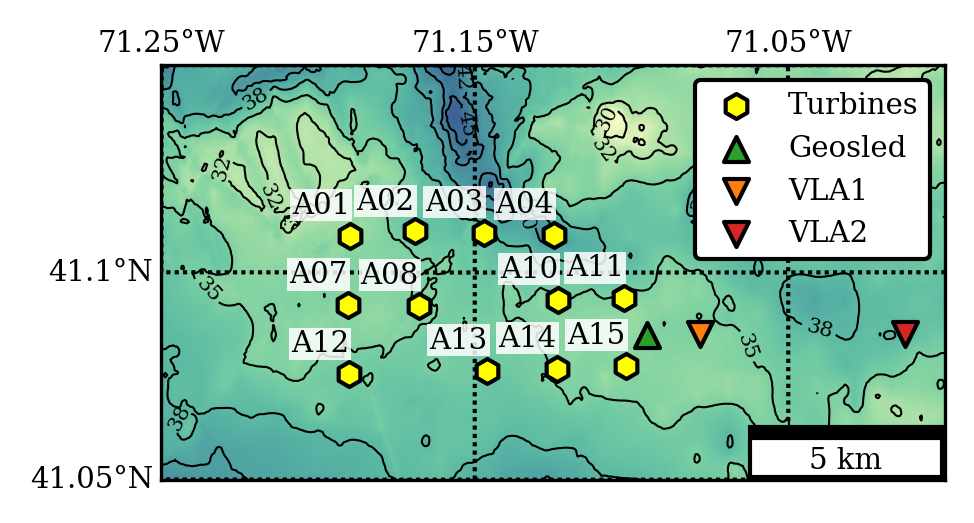

In [5]:
fig = plt.figure(figsize=(3.37, 2), dpi=300)
ax = plt.gca()

m = Basemap(
    projection="tmerc",
    llcrnrlat=bounds[1][0],
    urcrnrlat=bounds[1][1],
    llcrnrlon=bounds[0][0],
    urcrnrlon=bounds[0][1],
    resolution="i",
    lon_0=np.mean(lonvec),
    lat_0=np.mean(latvec),
)
m.drawmeridians(np.arange(bounds[0][0], bounds[0][1], 0.1), labels=[0, 0, 1, 0], ax=ax)
m.drawparallels(np.arange(bounds[1][0], bounds[1][1], 0.05), labels=[1, 0, 0, 0], ax=ax)
xlim = m(np.array(bounds[0]), np.ones_like(bounds[0]) * np.mean(bounds[1]))[0]
ylim = m(np.ones_like(bounds[0]) * np.mean(bounds[0]), np.array(bounds[1]))[1]

im, ax = plot_bathy(
    data,
    lonvec=m(lonvec, np.ones_like(lonvec) * np.mean(latvec))[0],
    latvec=m(np.ones_like(latvec) * np.mean(lonvec), latvec)[1],
    ax=ax,
)
[
    ax.scatter(
        *m(turbines_df.iloc[i]["lon"], turbines_df.iloc[i]["lat"]),
        marker="h",
        c="yellow",
        edgecolors="k",
        # linewidth=1,
        # s=150,
        zorder=50,
        label=turbines_df.iloc[i]["Turbine"]
    )
    for i in range(len(turbines_df))
]
texts = [
    ax.text(
        *m(turbines_df.iloc[i]["lon"], turbines_df.iloc[i]["lat"] + 0.004),
        turbines_df.iloc[i]["Turbine"],
        # fontsize=plt.rcParams["legend.fontsize"],

        ha="right",
        va="bottom",
        zorder=50,
        bbox=dict(facecolor="w", alpha=0.85, edgecolor="none", pad=0.5),
    )
    for i in range(len(turbines_df))
]
ax.scatter(
    *m(geo_equipment_df["Longitude [dd]"], geo_equipment_df["Latitude [dd]"]),
    marker="^",
    c="tab:green",
    edgecolors="k",
    # linewidth=1,
    # s=150,
    zorder=50,
    label="Geosled"
)
ax.scatter(
    *m(vla_equipment_df.iloc[0]["Longitude [dd]"], vla_equipment_df.iloc[0]["Latitude [dd]"]),
    marker="v",
    c="tab:orange",
    edgecolors="k",
    # linewidth=1,
    # s=150,
    zorder=50,
    label="VLA 1"
)
ax.scatter(
    *m(vla_equipment_df.iloc[1]["Longitude [dd]"], vla_equipment_df.iloc[1]["Latitude [dd]"]),
    marker="v",
    c="tab:red",
    edgecolors="k",
    # linewidth=1,
    # s=150,
    zorder=50,
    label="VLA 2"
)

ax.set_xlim(xlim)
ax.set_ylim(ylim)

# leg = ax.legend(facecolor="white", edgecolor="black", loc="upper right")
# Make the legend so it only shows one symbol for all the turbines
handles, labels = ax.get_legend_handles_labels()
labels = ["Turbines", "Geosled", "VLA1", "VLA2"]
# handles = handles[:3]
leg = ax.legend(
    handles[-4:], labels, facecolor="white", edgecolor="black", loc="upper right"
)
leg.get_frame().set_alpha(None)

scalebar = AnchoredSizeBar(
    ax.transData,
    5000,
    "5 km",
    "lower right",
    pad=0.1,
    color="k",
    frameon=True,
    size_vertical=200,
)
ax.add_artist(scalebar)

plt.show()
fig.savefig("reports/manuscripts/JASA/fig01a.pdf", dpi=600, bbox_inches="tight", pad_inches=0.0)